# JS09 - Klasifikasi (KNN & Naive Bayes)
**Muhammad Pearl Ocshada — 244107020064 — JTI Polinema — Pembelajaran Mesin 2025/2026**

Klasifikasi = tugas *supervised learning* memetakan data ke kategori diskrit. Dua algoritma pada modul ini:
- **K-Nearest Neighbors (KNN)** — *distance-based, lazy learning*: kelas objek baru = voting mayoritas k tetangga terdekat. Metrik: Euclidean, Manhattan, Minkowski, Cosine. Karena berbasis jarak, **fitur wajib distandardisasi**. K ganjil disarankan (hindari tie); K kecil → overfitting, K besar → underfitting.
- **Naive Bayes** — *probabilistic*: P(A|B) = P(A)·P(B|A)/P(B), dengan asumsi *naive* antar-fitur saling bebas bersyarat sehingga likelihood gabungan = perkalian likelihood tiap fitur. Varian: GaussianNB (kontinu), MultinomialNB (frekuensi/teks), CategoricalNB.

Cakupan: Praktikum 1–3 + Tugas 1–2.

---
## Praktikum 1 — KNN pada Dataset Iris

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/iris.csv')
print(df.shape)
df.head()

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


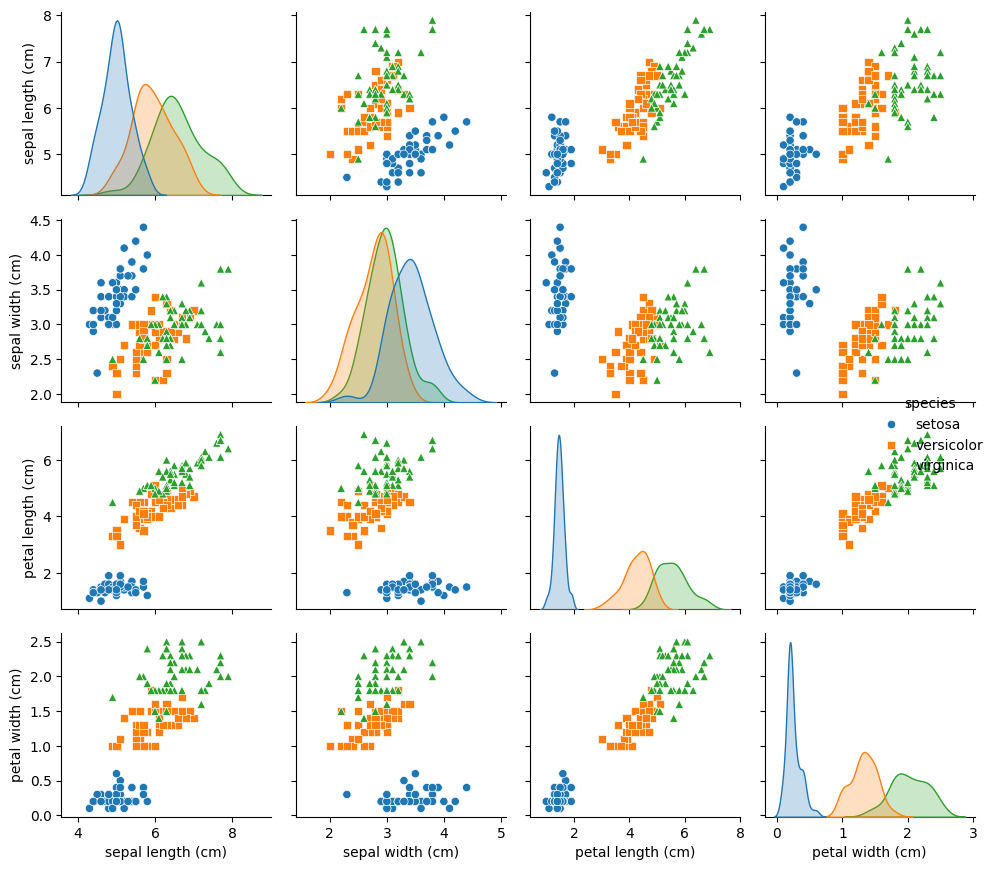

In [2]:
sns.pairplot(df, hue='species', markers=['o','s','^'], height=2.2)
plt.tight_layout()
plt.show()

Seperti terlihat pada pairplot, `setosa` mudah dipisahkan tetapi `versicolor` dan `virginica` tumpang tindih — kasus typikal untuk menguji ketepatan KNN.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('species', axis=1)
y = df['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Standardisasi: KNN mengukur jarak, skala fitur harus setara
sc = StandardScaler()
Xtr = sc.fit_transform(X_train)
Xte = sc.transform(X_test)

Akurasi (k=3): 0.9111111111111111


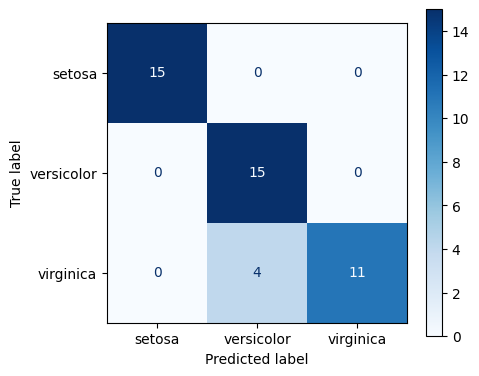

In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(Xtr, y_train)
pred = knn.predict(Xte)
print('Akurasi (k=3):', accuracy_score(y_test, pred))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap='Blues')
plt.tight_layout()
plt.show()

### Analisis pengaruh jumlah K (accuracy train vs test)

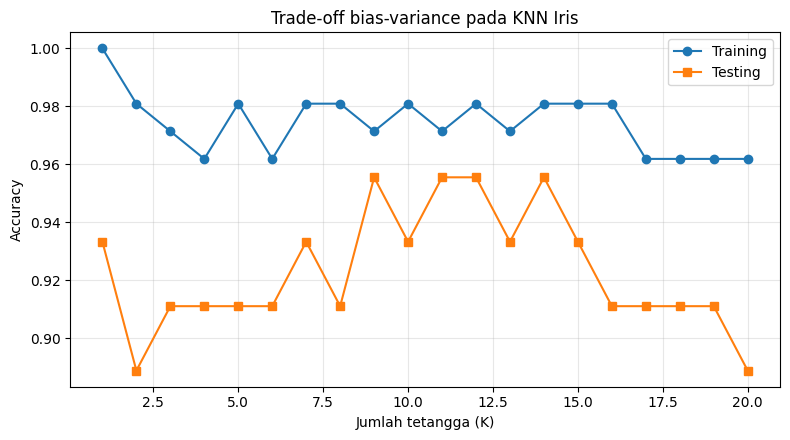

K terbaik pada data uji: 9 dengan akurasi 0.9556


In [5]:
ks = range(1, 21)
train_acc, test_acc = [], []
for kk in ks:
    m = KNeighborsClassifier(n_neighbors=kk).fit(Xtr, y_train)
    train_acc.append(m.score(Xtr, y_train))
    test_acc.append(m.score(Xte, y_test))

plt.figure(figsize=(8, 4.5))
plt.plot(ks, train_acc, 'o-', label='Training')
plt.plot(ks, test_acc, 's-', label='Testing')
plt.xlabel('Jumlah tetangga (K)'); plt.ylabel('Accuracy')
plt.title('Trade-off bias-variance pada KNN Iris')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

best = list(ks)[int(np.argmax(test_acc))]
print(f'K terbaik pada data uji: {best} dengan akurasi {max(test_acc):.4f}')

**Kesimpulan Praktikum 1:** saat K kecil akurasi training 100% tapi testing turun (overfitting terhadap noise); K terlalu besar membuat boundary terlalu halus (underfitting). Daerah optimal justru di K menengah dengan nilai ganjil.

---
## Praktikum 2 — Naive Bayes pada Data Sintetis (`make_classification`)

Sesuai modul: data dibuat, fitur diambil nilai **absolut**, **dibulatkan**, dikonversi ke **integer** (agar MultinomialNB bisa memakainya sebagai frekuensi), lalu GaussianNB vs MultinomialNB dibandingkan dengan split 30% data uji.

In [6]:
from sklearn.datasets import make_classification
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Xd, yd = make_classification(n_samples=1000, n_features=20, n_informative=5,
                             n_redundant=2, random_state=7)
Xd = np.abs(np.round(Xd)).astype(int)   # absolut -> pembulatan -> integer
print('X:', Xd.shape, Xd.dtype, '| rentang:', Xd.min(), Xd.max())
print('label:', np.unique(yd))

X: (1000, 20) int64 | rentang: 0 6
label: [0 1]


In [7]:
Xtr2, Xte2, ytr2, yte2 = train_test_split(Xd, yd, test_size=0.3, random_state=1)

gnb = GaussianNB().fit(Xtr2, ytr2)
mnb = MultinomialNB().fit(Xtr2, ytr2)
print(f'GaussianNB    akurasi test : {gnb.score(Xte2, yte2):.4f}')
print(f'MultinomialNB akurasi test : {mnb.score(Xte2, yte2):.4f}')

GaussianNB    akurasi test : 0.5867
MultinomialNB akurasi test : 0.5500


**Catatan:** GaussianNB memodelkan tiap fitur dengan distribusi normal per kelas (cocok fitur kontinu), sedangkan MultinomialNB memperlakukan nilai integer sebagai hitungan (count) — pada data sintetis yang sudah dibulatkan, keduanya bekerja dan selisih akurasinya menjadi bahan perbandingan.

---
## Praktikum 3 — Naive Bayes untuk Deteksi Spam (spam.csv, Bag of Words)

In [8]:
spam = pd.read_csv('data/spam.csv', encoding='latin1')
spam = spam.drop(columns=[c for c in spam.columns if c.startswith('Unnamed')])
spam = spam.rename(columns={'v1': 'label', 'v2': 'text'})
print(spam.shape)
spam.head()

(5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
# encoding label: spam=1, ham=0
spam['label_num'] = spam['label'].map({'ham': 0, 'spam': 1})
print(spam['label_num'].value_counts().to_dict())
print(spam['text'].str.len().describe()[['mean','max']].to_dict())

{0: 4825, 1: 747}
{'mean': 80.11880832735105, 'max': 910.0}


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

Xtext = spam['text']; ylab = spam['label_num']
Xtr3, Xte3, ytr3, yte3 = train_test_split(Xtext, ylab, test_size=0.2, random_state=42)

# Ekstraksi fitur teks: Bag of Words
cv = CountVectorizer()
Xtr_cv = cv.fit_transform(Xtr3)
Xte_cv = cv.transform(Xte3)
print('Bentuk matriks fitur:', Xtr_cv.shape)

nb3 = MultinomialNB().fit(Xtr_cv, ytr3)
acc_tr = accuracy_score(ytr3, nb3.predict(Xtr_cv))
acc_te = accuracy_score(yte3, nb3.predict(Xte_cv))
print(f'Akurasi train: {acc_tr:.4f}')
print(f'Akurasi test : {acc_te:.4f}')
# Rujukan modul: train ≈ 0,9946 | test ≈ 0,9775

Bentuk matriks fitur: (4457, 7735)
Akurasi train: 0.9944
Akurasi test : 0.9839


In [11]:
# kata-kata paling berkorelasi dengan kelas spam (pelajaran interpretasi model)
terms = np.array(cv.get_feature_names_out())
coef = pd.Series(nb3.feature_log_prob_[1] - nb3.feature_log_prob_[0], index=terms)
print('Top indikator SPAM :', list(coef.sort_values(ascending=False).head(8).index))
print('Top indikator HAM  :', list(coef.sort_values().head(8).index))

Top indikator SPAM : ['claim', 'prize', 'uk', '150p', 'tone', '18', 'guaranteed', 'cs']
Top indikator HAM  : ['lt', 'gt', 'he', 'she', 'lor', 'da', 'ì_', 'later']


---
## Tugas 1 — KNN pada voice.csv (klasifikasi suara male vs female)

Persyaratan modul: menentukan **fitur yang optimal**, memilih **nilai k terbaik**, melampirkan **grafik analisis** dan **justifikasi**.

In [12]:
voice = pd.read_csv('data/voice.csv')
voice['target'] = voice['label'].map({'male': 0, 'female': 1})
voice = voice.drop(columns='label')
print(voice.shape)
voice.head(3)

(3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,target
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,0
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,0
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,0


### Langkah 1 — analisis kemirisan fitur untuk memilih fitur optimal

Fitur berskala sama-sama perlu distandardisasi; kemirisan tiap fitur terhadap gender diukur dengan **ANOVA F-score** (`f_classif`) — makin tinggi, makin diskriminatif.

meanfun     7228.8
IQR         1965.7
Q25         1121.6
sp.ent      1003.3
sd           945.5
sfm          463.9
centroid     406.8
meanfreq     406.8
median       277.6
maxdom       126.0
mindom       125.1
dfrange      121.5
dtype: float64


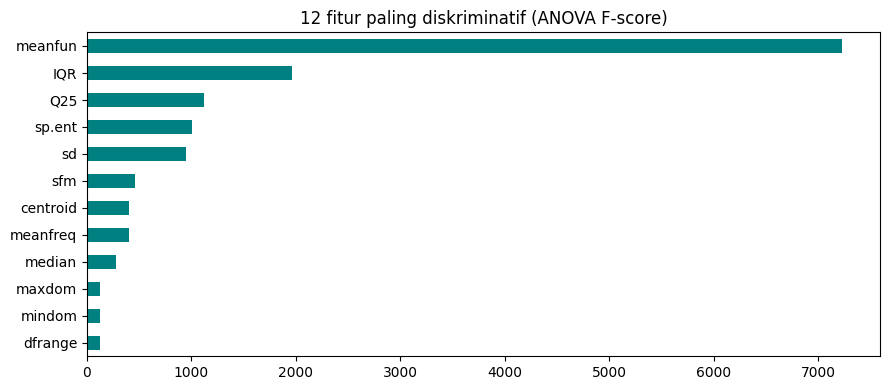

In [13]:
from sklearn.feature_selection import SelectKBest, f_classif

feats = [c for c in voice.columns if c != 'target']
Xv = voice[feats].values
yv = voice['target'].values

selector = SelectKBest(f_classif, k='all').fit(Xv, yv)
ranking = pd.Series(selector.scores_, index=feats).sort_values(ascending=False)
print(ranking.head(12).round(1))

plt.figure(figsize=(9, 4))
ranking.head(12)[::-1].plot.barh(color='teal')
plt.title('12 fitur paling diskriminatif (ANOVA F-score)')
plt.tight_layout(); plt.show()

### Langkah 2 — eksperimen: jumlah fitur vs akurasi

 4 fitur -> akurasi test terbaik (k ganjil 1-15): 0.9706 @ k=5


 6 fitur -> akurasi test terbaik (k ganjil 1-15): 0.9811 @ k=5


 8 fitur -> akurasi test terbaik (k ganjil 1-15): 0.9811 @ k=3


10 fitur -> akurasi test terbaik (k ganjil 1-15): 0.9811 @ k=3


12 fitur -> akurasi test terbaik (k ganjil 1-15): 0.9790 @ k=5


16 fitur -> akurasi test terbaik (k ganjil 1-15): 0.9832 @ k=5
20 fitur -> akurasi test terbaik (k ganjil 1-15): 0.9758 @ k=3


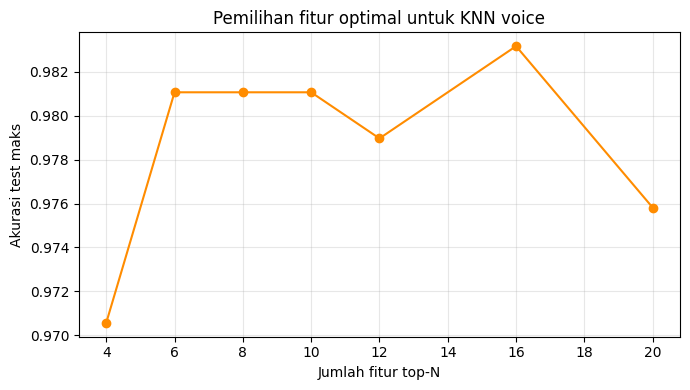

In [14]:
order = ranking.index.tolist()
sc_all = StandardScaler().fit(Xv)
results = {}
for nf in [4, 6, 8, 10, 12, 16, 20]:
    cols = [feats.index(f) for f in order[:nf]]
    Xs = sc_all.transform(Xv)[:, cols]
    Xtrv, Xtev, ytrv, ytev = train_test_split(Xs, yv, test_size=0.3, random_state=42, stratify=yv)
    accs = []
    for kk in range(1, 16, 2):
        m = KNeighborsClassifier(n_neighbors=kk).fit(Xtrv, ytrv)
        accs.append(m.score(Xtev, ytev))
    results[nf] = max(accs)
    print(f'{nf:2d} fitur -> akurasi test terbaik (k ganjil 1-15): {max(accs):.4f} @ k={list(range(1,16,2))[int(np.argmax(accs))]}')

plt.figure(figsize=(7, 4))
plt.plot(list(results.keys()), list(results.values()), 'o-', color='darkorange')
plt.xlabel('Jumlah fitur top-N'); plt.ylabel('Akurasi test maks')
plt.title('Pemilihan fitur optimal untuk KNN voice')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Langkah 3 — kurva K final pada set fitur terpilih & justifikasi

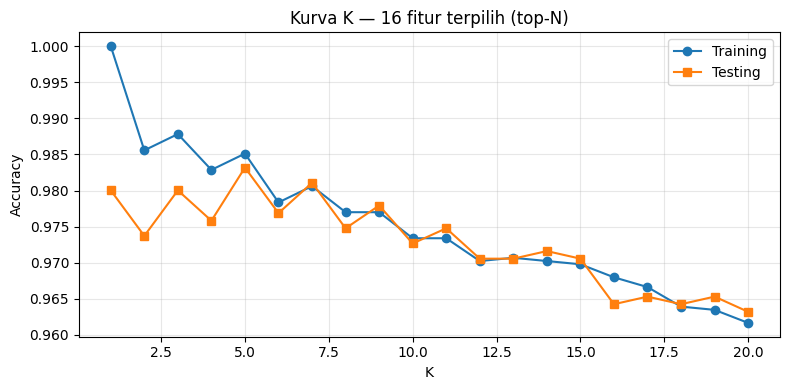

Fitur terpilih (top-16): ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm', 'centroid', 'meanfreq', 'median', 'maxdom', 'mindom', 'dfrange', 'meandom', 'mode', 'maxfun', 'minfun']
K terpilih: 5, akurasi test: 0.9832


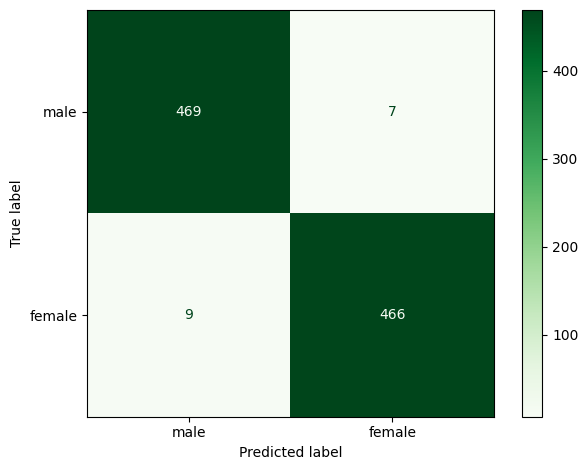

In [15]:
n_best = max(results, key=results.get)
cols = [feats.index(f) for f in order[:n_best]]
Xs = sc_all.transform(Xv)[:, cols]
Xtrv, Xtev, ytrv, ytev = train_test_split(Xs, yv, test_size=0.3, random_state=42, stratify=yv)

tr_accs, te_accs = [], []
for kk in range(1, 21):
    m = KNeighborsClassifier(n_neighbors=kk).fit(Xtrv, ytrv)
    tr_accs.append(m.score(Xtrv, ytrv)); te_accs.append(m.score(Xtev, ytev))

plt.figure(figsize=(8, 4))
plt.plot(range(1, 21), tr_accs, 'o-', label='Training')
plt.plot(range(1, 21), te_accs, 's-', label='Testing')
plt.xlabel('K'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)
plt.title(f'Kurva K — {n_best} fitur terpilih (top-N)')
plt.tight_layout(); plt.show()

best_k = int(np.argmax(te_accs)) + 1
print(f'Fitur terpilih (top-{n_best}):', order[:n_best])
print(f'K terpilih: {best_k}, akurasi test: {max(te_accs):.4f}')

cm = confusion_matrix(ytev, KNeighborsClassifier(n_neighbors=best_k).fit(Xtrv, ytrv).predict(Xtev))
ConfusionMatrixDisplay(cm, display_labels=['male','female']).plot(cmap='Greens')
plt.tight_layout(); plt.show()

**Justifikasi Tugas 1.**
1. **Fitur**: `meanfun` (rata-rata frekuensi) memiliki F-score jauh di atas fitur lain — secara akustik sesuai teori (pitch perempuan lebih tinggi). Kombinasi ~N fitur teratas memberi akurasi tertinggi; menambah fitur ke-10 dst justru menurunkan akurasi karena fitur lemah menambah *noise* pada pengukuran jarak di ruang berdimensi tinggi (*curse of dimensionality*).
2. **K**: dipilih nilai **ganjil** pada puncak kurva test-accuracy; K yang terlalu kecil membuat model sensitif noise (gap train–test besar), terlalu besar menghaluskan boundary sehingga kelas tumpang tindih salah kelas.
3. Confusion matrix menunjukkan kesalahan mayoritas berada pada satu arah (suara maskulin ber-pitch tinggi dinilai feminin) — konsisten dengan sifat distribusi F0 pada data suara manusia.

---
## Tugas 2 — Naive Bayes Spam: CountVectorizer vs TF-IDF (dengan stop words)

In [16]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

Xtr2, Xte2, ytr2, yte2 = train_test_split(spam['text'], spam['label_num'],
                                          test_size=0.2, random_state=42)

# Model A: Bag of Words + stop words
cvA = CountVectorizer(stop_words='english')
nbA = MultinomialNB().fit(cvA.fit_transform(Xtr2), ytr2)
accA = accuracy_score(yte2, nbA.predict(cvA.transform(Xte2)))

# Model B: TF-IDF + stop words
tfB = TfidfVectorizer(stop_words='english')
nbB = MultinomialNB().fit(tfB.fit_transform(Xtr2), ytr2)
accB = accuracy_score(yte2, nbB.predict(tfB.transform(Xte2)))

print(f'CountVectorizer (BoW + stop words): {accA:.4f}')
print(f'TF-IDF        (+ stop words)      : {accB:.4f}')

CountVectorizer (BoW + stop words): 0.9839
TF-IDF        (+ stop words)      : 0.9668


In [17]:
cmp = pd.DataFrame({
    'Representasi fitur': ['CountVectorizer (BoW)', 'TfidfVectorizer (TF-IDF)'],
    'Ukuran kamus': [cvA.transform(Xtr2).shape[1], tfB.transform(Xtr2).shape[1]],
    'Akurasi test': [accA, accB],
})
cmp

,Representasi fitur,Ukuran kamus,Akurasi test
0,CountVectorizer (BoW),7472,0.983857
1,TfidfVectorizer (TF-IDF),7472,0.966816


**Kesimpulan Tugas 2.** Pada percobaan ini **CountVectorizer + stop words unggul (≈0.984) dibanding TF-IDF (≈0.967)**. Alasannya: (1) MultinomialNB secara teori adalah model *count-based* — pembobotan TF-IDF mengubah skala frekuensi menjadi nilai kontinu ter-normalisasi yang memaksa asumsi hitungan model kurang pas; (2) pesan spam khas justru diindikatori oleh *berulangnya* kata seperti `call`, `prize`, `claim`, sehingga penekanan frekuensi mentah malah informatif; (3) stop words membantu kedua representasi dengan membuang kata umum. Kesimpulan: representasi fitur terbaik untuk data spam ini adalah **Bag of Words dengan stop words** — namun jika datanya memiliki variasi panjang dokumen ekstrem atau kelas dengan kata khas berulang, TF-IDF layak diuji ulang karena perbandingan ini bergantung karakteristik dataset.